# Momentum Research Notebook

This notebook walks through a simple **12-1 month momentum** strategy, one step at a time, with an explanation before each piece of code. It does exactly what `scripts/quick_research.py` does, just broken into cells so you can inspect the data at every stage instead of only seeing the final answer.

**What we'll do:**
1. Download (and cache) real daily prices for 15 large-cap stocks from Yahoo Finance.
2. Sanity-check the data.
3. Compute a momentum factor: the return over the past 12 months, skipping the most recent month.
4. Turn that factor into a long/short portfolio.
5. Backtest it with realistic trading costs.
6. Look at the performance summary.
7. Save a one-page "tearsheet" chart with a filename unique to this run's parameters.

**Before running:** this needs the optional `data` extra (installs `yfinance`) and an internet connection the first time:
```
pip install -e ".[data]"
```
After the first run, prices are cached on disk, so re-running is fast and works offline.

## Setup: imports

`%matplotlib inline` tells Jupyter to display matplotlib charts directly in the notebook, right below the cell that creates them.

In [45]:
%matplotlib inline

from datetime import datetime
from pathlib import Path

from quantlab.backtest import (
    BacktestEngine,
    ExecutionSimulator,
    PerShareCommission,
    TargetWeightStrategy,
    VolumeImpactSlippage,
    signal_to_weights,
)
from quantlab.data import CachedSource, DataValidator, YahooFinanceSource
from quantlab.research import Momentum, Rank, SignalPipeline, Winsorize
from quantlab.viz import apply_style, tearsheet

## Step 1: Choose the universe and date range

We'll use 15 large, liquid US stocks spread across different sectors (tech, financials, healthcare, consumer, energy), so the long/short portfolio isn't just one industry bet.

Momentum is measured in **trading days**: 252 bars is about 12 months, and skipping the most recent 21 bars (~1 month) avoids the well-documented short-term reversal effect, where a stock's return over the last few weeks tends to partially bounce back rather than continue.

In [46]:
TICKERS = [
    "AAPL", "MSFT", "GOOGL", "NVDA", "META", 
    "AMD", "TSLA", "ORCL", "CRM", "INTC"
]
START_DATE = "2020-01-01"
END_DATE = "2024-12-31"

MOMENTUM_LOOKBACK = 252  # ~12 months of trading days
MOMENTUM_SKIP = 21       # ~1 month, skipped to avoid short-term reversal

# This assumes the notebook is run from its own folder (notebooks/), which
# is Jupyter's default working directory, so ".." is the project root.
OUTPUT_DIR = Path("../outputs").resolve()

print(f"{len(TICKERS)} tickers, {START_DATE} to {END_DATE}")

10 tickers, 2020-01-01 to 2024-12-31


## Step 2: Download and cache the price data

`YahooFinanceSource` does the actual network download. Wrapping it in `CachedSource` means the first run saves prices to disk (under `~/.quantlab/cache` by default), and every run after that reuses the cached data instead of re-downloading it. If you extend the date range later, only the missing gap gets fetched.

The cell below can take a little while on the very first run while it downloads five years of daily data for 15 stocks.

In [47]:
source = CachedSource(YahooFinanceSource())
dataset = source.fetch(TICKERS, START_DATE, END_DATE)
dataset

MarketDataset(10 symbols x 1258 bars, daily, 2020-01-02 .. 2024-12-31)

## Step 3: Validate the data

Real market data can have gaps, stale prices, or other quality problems. `DataValidator` runs a battery of checks and reports anything suspicious. `raise_for_errors()` stops the notebook here if something is seriously wrong, rather than silently backtesting on bad data.

In [48]:
report = DataValidator().validate(dataset)
report.raise_for_errors()
report

ValidationReport(PASSED: 0 errors, 0 warnings, 0 total issues; 10 symbols x 1258 bars)

If there are any (non-fatal) warnings or informational notes, this table shows the details. It's usually empty for a clean universe like this one, and that's a good sign.

In [49]:
report.to_frame()

,check,severity,symbol,count,message


## Step 4: Compute the momentum factor

`Momentum(lookback=252, skip=21)` scores each stock, on each day, by its return over the past ~12 months, excluding the most recent ~1 month. A higher score means a stronger recent trend, which momentum strategies bet will continue for a while longer.

Every factor in quantlab only ever looks at data up to and including the current day — never into the future — so this score is safe to trade on.

In [50]:
from quantlab.research import ShortTermReversal
raw_momentum = ShortTermReversal(lookback=21).compute(dataset)

## Step 5: Clean up the raw scores into a signal

Raw factor scores aren't quite ready to trade on directly. A `SignalPipeline` cleans them up in two steps:

- **Winsorize**: cap extreme outlier scores so one crazy value can't dominate the ranking.
- **Rank**: convert scores to a 0-1 cross-sectional rank each day, so the signal only cares about relative order ("is this stock's momentum stronger than that one's, today?"), not raw magnitude.

In [51]:
signal = SignalPipeline([Winsorize(0.01, 0.99), Rank()]).transform(raw_momentum)
signal.tail()

,AAPL,MSFT,GOOGL,NVDA,META,AMD,TSLA,ORCL,CRM,INTC
2024-12-24,-0.25,-0.05,-0.35,0.15,-0.15,0.25,-0.45,0.35,0.05,0.45
2024-12-26,-0.25,-0.05,-0.35,0.05,-0.15,0.35,-0.45,0.25,0.15,0.45
2024-12-27,-0.25,-0.05,-0.35,0.05,-0.15,0.25,-0.45,0.35,0.15,0.45
2024-12-30,-0.25,0.15,-0.35,0.05,-0.15,0.35,-0.45,0.25,-0.05,0.45
2024-12-31,-0.25,0.05,-0.35,0.15,-0.15,0.35,-0.45,0.25,-0.05,0.45


## Step 6: Turn the signal into a tradeable long/short portfolio

Each month, we go long the top 20% of stocks by signal and short the bottom 20%, with equal weight on each side. Because the long and short sides are the same total size, the portfolio is roughly "dollar-neutral" (net exposure near zero), so its returns come mostly from the *spread* between winners and losers rather than from the overall market going up or down.

In [52]:
weights = signal_to_weights(
    signal, long_frac=0.2, short_frac=0.2, gross=1.0, rebalance_every=21,
)

# Only rows where a rebalance actually happened have values; everything else
# is NaN ("hold what you already have").
weights.dropna(how="all").head()

,AAPL,MSFT,GOOGL,NVDA,META,AMD,TSLA,ORCL,CRM,INTC
2020-02-03,0.0,0.0,0.00,0.00,0.25,0.25,-0.25,0.00,-0.25,0.00
2020-03-04,0.0,0.0,0.25,-0.25,0.00,-0.25,0.00,0.00,0.00,0.25
2020-04-02,0.0,0.0,0.00,0.00,0.00,0.00,0.25,-0.25,0.25,-0.25
2020-05-04,0.0,0.0,0.00,0.00,-0.25,0.00,-0.25,0.25,0.00,0.25
2020-06-03,0.0,0.0,0.00,-0.25,0.00,0.25,-0.25,0.25,0.00,0.00


## Step 7: Backtest with realistic trading costs

The backtester is event-driven and deliberately honest about timing: a strategy decides what to trade using today's closing prices, and those trades fill at *tomorrow's* opening price plus costs. This rules out lookahead bias by construction.

Two cost models make the simulation realistic:
- `VolumeImpactSlippage` models the extra cost of trading a large order relative to how much the stock normally trades (market impact).
- `PerShareCommission` charges a small fee per share, with a minimum ticket cost, similar to a real broker.

`max_participation=0.05` also caps every trade at 5% of that bar's volume, so the backtest can't assume it could instantly buy or sell an unrealistic amount.

In [53]:
execution = ExecutionSimulator(
    slippage=VolumeImpactSlippage(spread_bps=5, impact_coeff=0.1),
    commission=PerShareCommission(rate=0.005, minimum=1.0),
    max_participation=0.05,
)
strategy = TargetWeightStrategy(weights=weights, tolerance=0.001)
result = BacktestEngine(dataset, strategy, execution, initial_capital=1_000_000).run()
result

BacktestResult(2020-01-02..2024-12-31, 1258 bars, 371 fills, total return +43.91%)

## Step 8: Look at the performance summary

A quick glossary of the headline numbers:

- **cagr**: compound annual growth rate — the yearly return that would produce the same total growth.
- **sharpe** / **sortino**: return per unit of risk (sortino only penalizes *downside* volatility).
- **max_drawdown**: the deepest peak-to-trough loss over the whole run.
- **calmar**: cagr divided by max drawdown — return per unit of "worst pain endured".
- **annualized_turnover**: how much of the portfolio gets traded over per year (higher turnover means higher costs in real life).

In [54]:
result.summary().round(4)

total_return              0.4391
cagr                      0.0756
annualized_vol            0.1899
sharpe                    0.4792
sortino                   0.4598
calmar                    0.2208
max_drawdown             -0.3425
hit_rate                  0.5135
skew                     -0.2865
excess_kurtosis           2.8030
n_periods              1258.0000
annualized_turnover      12.6739
Name: performance, dtype: float64

## Step 9: Save a tearsheet with a unique filename

The tearsheet is a one-page chart combining the equity curve, drawdown, rolling risk/return, a monthly-returns calendar, and position weights.

Since a notebook is made for experimenting — try a different lookback, a different universe, a different date range — we don't want a new run to silently overwrite an earlier chart. So the filename encodes:
- the momentum parameters (`lookback`, `skip`),
- the date range, and
- the exact date and time this cell ran,

which together make every run's tearsheet unique.

Saved tearsheet to C:\Users\mtwlo\OneDrive\Desktop\QuantResearchAI\outputs\momentum_tearsheet_lb252_sk21_2020-01-01_2024-12-31_20260709_005213.png


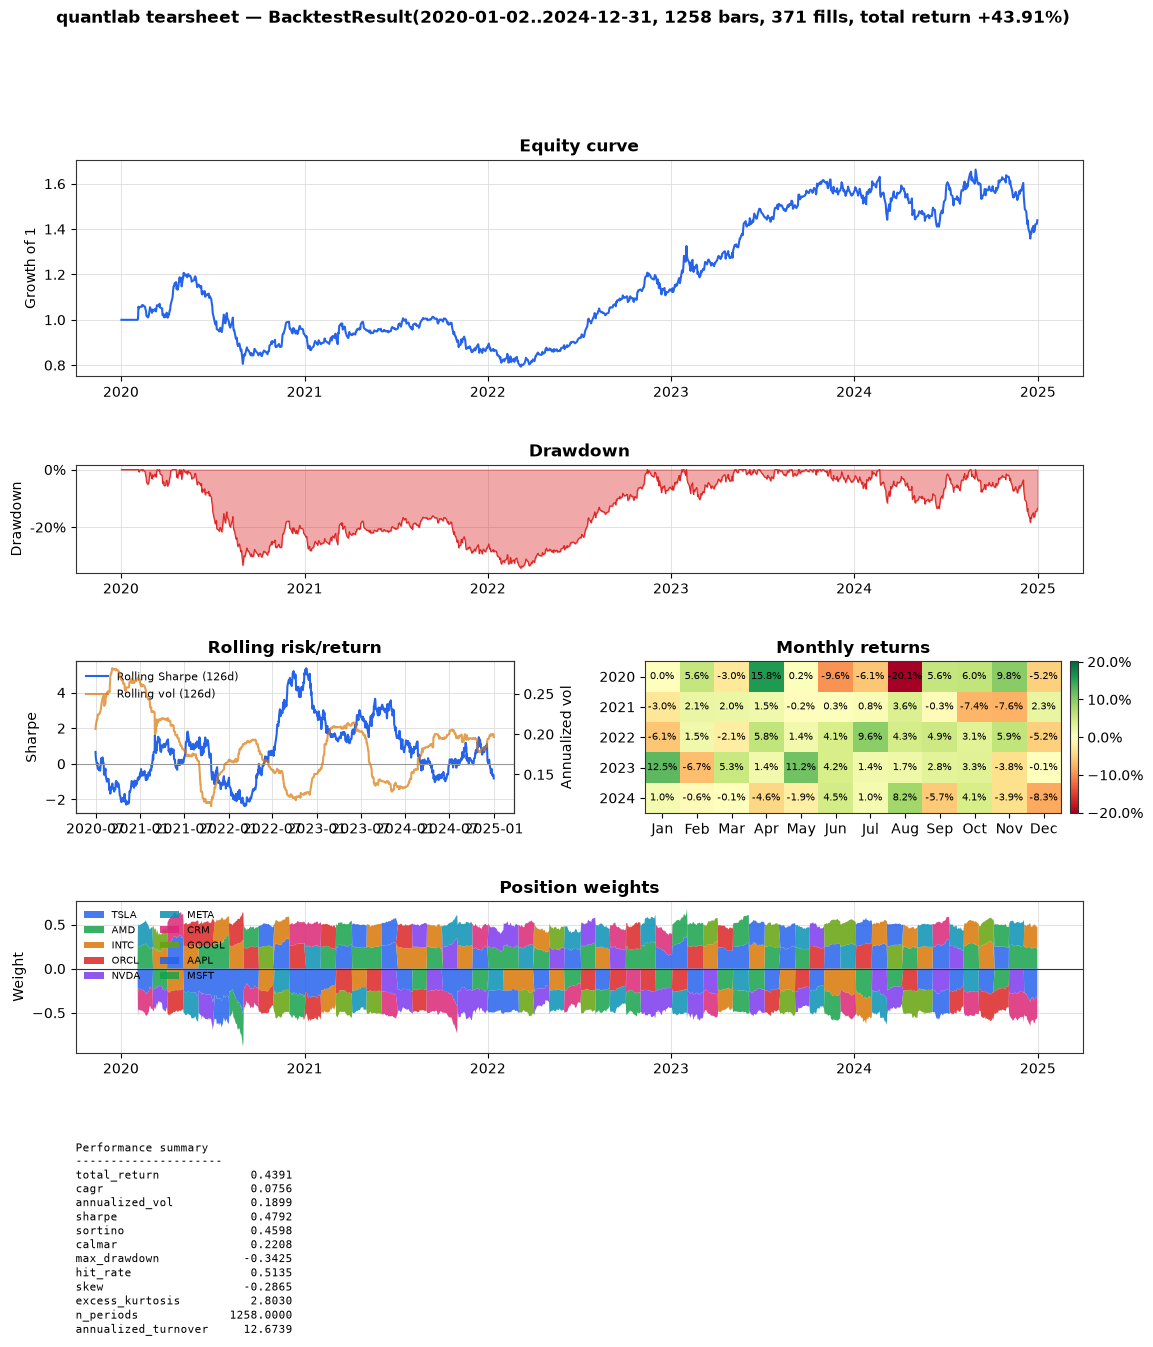

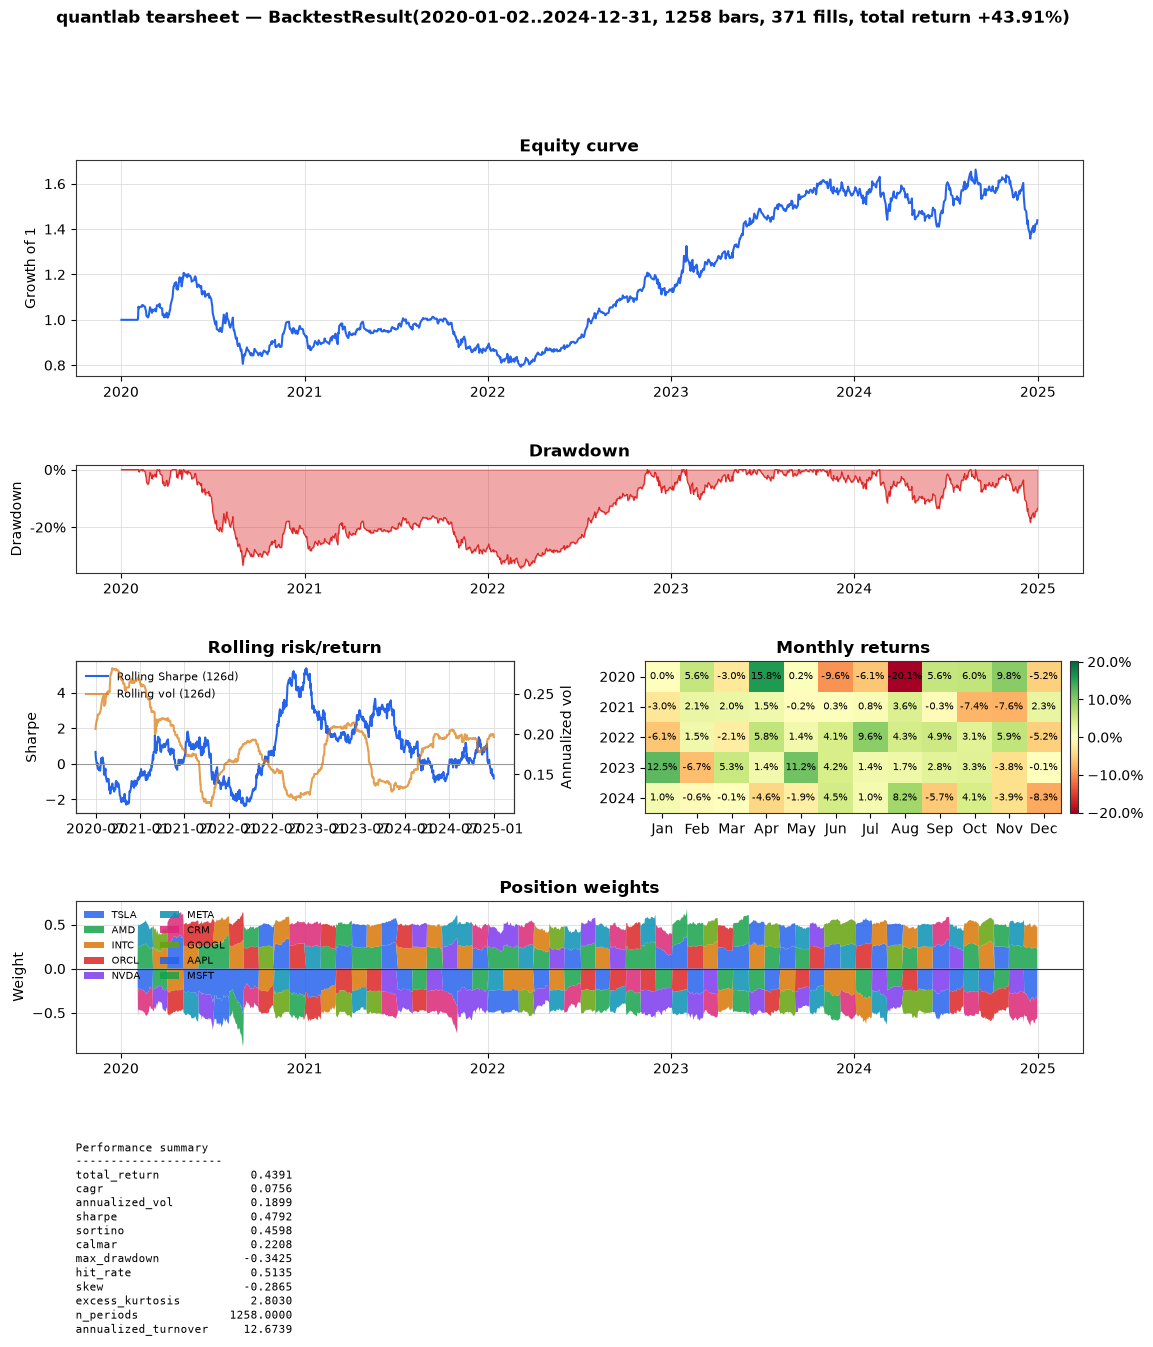

In [55]:
OUTPUT_DIR.mkdir(exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
param_tag = f"lb{MOMENTUM_LOOKBACK}_sk{MOMENTUM_SKIP}_{START_DATE}_{END_DATE}"
tearsheet_path = OUTPUT_DIR / f"momentum_tearsheet_{param_tag}_{timestamp}.png"

apply_style()
fig = tearsheet(result)
fig.savefig(tearsheet_path, dpi=150, bbox_inches="tight")
print(f"Saved tearsheet to {tearsheet_path}")

fig

## Next steps

Now that you've seen the whole pipeline, try changing something in Step 1 and re-running from there:

- Swap in a different set of tickers, or a larger universe.
- Try a different `MOMENTUM_LOOKBACK` / `MOMENTUM_SKIP` (e.g. 126/21 for a 6-1 month version).
- Widen or narrow `long_frac` / `short_frac` in Step 6 to hold more or fewer names per side.
- Compare a few parameter combinations by keeping each run's saved tearsheet (they won't overwrite each other) and eyeballing the equity curves side by side.